# Podstawy AI – Sterownik wentylatora w języku FCL

**FCL** (*Fuzzy Control Language*, norma IEC 61131-7) to standardowy, tekstowy format opisu sterowników rozmytych, używany w przemyśle. Plik FCL zawiera wszystko, co sterownik wie: zmienne, funkcje przynależności, reguły i ustawienia operatorów.

**Potrzebne pliki** (w tym samym folderze co notebook; w Google Colab: ikona folderu po lewej → „Prześlij”):
- `wentylator.fcl` – sterownik do analizy,
- `fcl_narzedzie.py` – narzędzie, które czyta pliki FCL i liczy wynik.

Nic nie trzeba instalować – narzędzie używa tylko `numpy` i `matplotlib`, które są w Colab.

**Plan:**
1. Analiza pliku FCL (A–C)
2. Dodanie stanu `very_hot` i nowej reguły
3. Testy sterownika
4. Trzy konfiguracje: implikacja, wyostrzanie, suma zbiorów
5. Ocena sterownika
6. Drugie wejście: wilgotność

**Do oddania:** pliki FCL (co najmniej 3 konfiguracje i wersja z wilgotnością) oraz ten notebook zapisany jako PDF (Plik → Drukuj → Zapisz jako PDF).

In [2]:
from fcl_narzedzie import wynik, tabela, rysuj_zbiory, krzywa, wariant, rozszerz, krzywe
print(open("wentylator.fcl", encoding="utf-8").read())

(* Podstawy AI – sterownik rozmyty wentylatora
   Jedno wejście: temperatura, jedno wyjście: prędkość wentylatora. *)

FUNCTION_BLOCK wentylator

VAR_INPUT
    temperature : REAL;     (* temperatura w pomieszczeniu [°C] *)
END_VAR

VAR_OUTPUT
    fan_speed : REAL;       (* prędkość wentylatora [% mocy] *)
END_VAR

FUZZIFY temperature
    RANGE := (0 .. 40);
    TERM cold := (0, 1) (10, 1) (20, 0);
    TERM warm := (10, 0) (20, 1) (30, 0);
    TERM hot  := (20, 0) (30, 1) (40, 1);
END_FUZZIFY

DEFUZZIFY fan_speed
    RANGE := (0 .. 100);
    TERM low     := (0, 1) (20, 1) (45, 0);
    TERM medium  := (25, 0) (50, 1) (75, 0);
    TERM high    := (55, 0) (80, 1) (95, 0);
    TERM maximum := (85, 0) (100, 1);
    METHOD : COG;           (* wyostrzanie: środek ciężkości *)
    DEFAULT := 0;           (* wynik, gdy żadna reguła nie działa *)
END_DEFUZZIFY

RULEBLOCK reguly
    AND  : MIN;             (* "i" w części JEŚLI *)
    ACT  : MIN;             (* implikacja: MIN przycina, PROD skalu

---
## 1. Analiza pliku FCL

Plik składa się z bloków. Każdy odpowiada jednemu krokowi sterownika rozmytego:

| blok | co zawiera |
|---|---|
| `VAR_INPUT` / `VAR_OUTPUT` | nazwy wejść i wyjść |
| `FUZZIFY` | funkcje przynależności wejścia, zapisane punktami `(x, μ)` – łamana przez te punkty |
| `DEFUZZIFY` | funkcje przynależności wyjścia, metoda wyostrzania `METHOD`, wartość `DEFAULT` |
| `RULEBLOCK` | operatory (`AND`, `ACT` – implikacja, `ACCU` – suma zbiorów) i reguły `IF … THEN …` |

Przykład: `TERM cold := (0, 1) (10, 1) (20, 0);` znaczy: do 10 °C „zimno” w stopniu 1, potem stopień maleje liniowo do 0 przy 20 °C.

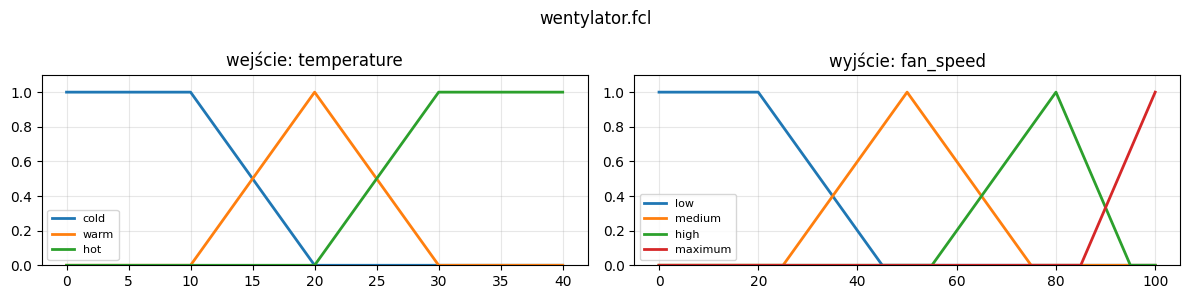

In [3]:
rysuj_zbiory("wentylator.fcl")

**Zadanie 1A.** Wypisz zmienne wejściowe i wyjściowe (nazwa, zakres, jednostka).

**Zadanie 1B.** Wypisz funkcje przynależności każdej zmiennej i opisz słowami, co znaczą (np. „cold – do 10 °C na pewno zimno, od 20 °C na pewno nie”).

**Zadanie 1C.** Wypisz reguły i opisz jednym zdaniem, jak działa ten sterownik.

*Twoja odpowiedź:*

1A:

| Zmienna | Rodzaj | Zakres | Jednostka |
|---|---|---:|---|
| temperature | wejściowa | 0–40 | °C |
| fan_speed | wyjściowa | 0–100 | % mocy |

1B:
Zmienna temperature:
- cold – pełna przynależność od 0 do 10°C, następnie maleje liniowo do 0 przy 20°C.
- warm – przynależność rośnie od 0 przy 10°C do 1 przy 20°C, a następnie maleje do 0 przy 30°C.
- hot – przynależność rośnie od 0 przy 20°C do 1 przy 30°C i pozostaje równa 1 do 40°C.

Zmienna fan_speed:
- low – pełna przynależność od 0 do 20%, następnie maleje do 0 przy 45%.
- medium – maksymalna przynależność przy 50%; spada do 0 przy 25% i 75%.
- high – maksymalna przynależność przy 80%; spada do 0 przy 55% i 95%.
- maximum – przynależność rośnie od 0 przy 85% do 1 przy 100%.

1C:
1. IF temperature IS cold THEN fan_speed IS low;
2. IF temperature IS warm THEN fan_speed IS medium;
3. IF temperature IS hot THEN fan_speed IS high;

Sterownik wentylatora działa na podstawie temperatury w pomieszczeniu. Gdy temperatura jest niska, wentylator pracuje z małą prędkością. Przy temperaturze umiarkowanej zwiększa prędkość do średniej, a przy wysokiej temperaturze pracuje z dużą prędkością. Wynik jest obliczany za pomocą logiki rozmytej, dlatego zmiana prędkości odbywa się płynnie.


---
## 2. Dodanie stanu `very_hot`

Komórka poniżej zapisuje plik `wentylator_k1.fcl`. Na start zawiera kopię oryginału. Zmień go bezpośrednio w komórce:

1. **(A)** Dodaj do `temperature` stan `very_hot`. Pamiętaj, że `hot` i `very_hot` muszą się **nakładać**, a `hot` powinien przestać być płaski do 40 °C (inaczej przy 40 °C będzie jednocześnie w pełni „hot” i „very_hot”).
2. **(B)** Dodaj regułę: jeśli `very_hot`, to `fan_speed` = `maximum`.

Uruchom komórkę – zapisze plik. Potem uruchom następną, żeby zobaczyć wykres.

In [6]:
%%writefile wentylator_k1.fcl
(* TODO: dodaj stan very_hot i regułę dla niego *)

FUNCTION_BLOCK wentylator

VAR_INPUT
    temperature : REAL;     (* temperatura w pomieszczeniu [°C] *)
END_VAR

VAR_OUTPUT
    fan_speed : REAL;       (* prędkość wentylatora [% mocy] *)
END_VAR

FUZZIFY temperature
    RANGE := (0 .. 40);
    TERM cold := (0, 1) (10, 1) (20, 0);
    TERM warm := (10, 0) (20, 1) (30, 0);
    TERM hot  := (20, 0) (30, 1) (40, 1);
    TERM very_hot := (30, 0) (40, 1);
END_FUZZIFY

DEFUZZIFY fan_speed
    RANGE := (0 .. 100);
    TERM low     := (0, 1) (20, 1) (45, 0);
    TERM medium  := (25, 0) (50, 1) (75, 0);
    TERM high    := (55, 0) (80, 1) (95, 0);
    TERM maximum := (85, 0) (100, 1);
    METHOD : COG;           (* wyostrzanie: środek ciężkości *)
    DEFAULT := 0;           (* wynik, gdy żadna reguła nie działa *)
END_DEFUZZIFY

RULEBLOCK reguly
    AND  : MIN;             (* "i" w części JEŚLI *)
    ACT  : MIN;             (* implikacja: MIN przycina, PROD skaluje *)
    ACCU : MAX;             (* suma zbiorów na wyjściu: MAX, BSUM *)

    RULE 1 : IF temperature IS cold THEN fan_speed IS low;
    RULE 2 : IF temperature IS warm THEN fan_speed IS medium;
    RULE 3 : IF temperature IS hot  THEN fan_speed IS high;
    RULE 4 : IF temperature IS very_hot THEN fan_speed IS maximum;
END_RULEBLOCK

END_FUNCTION_BLOCK

Overwriting wentylator_k1.fcl


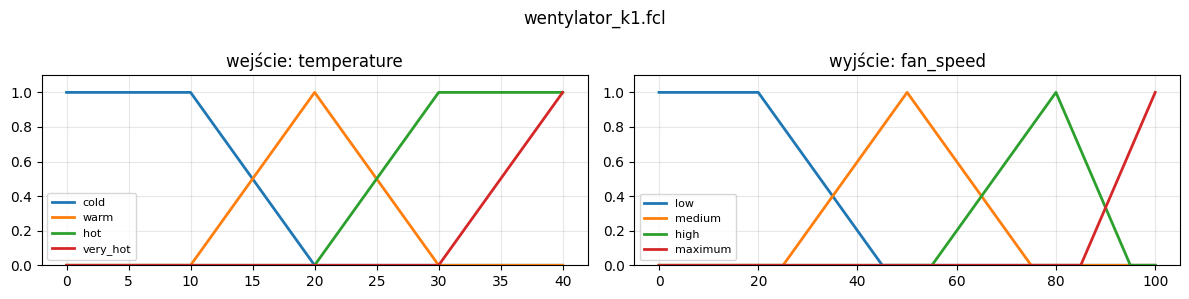

In [7]:
rysuj_zbiory("wentylator_k1.fcl")

---
## 3. Testy sterownika

**Zadanie 2C.** Porównaj oryginał i Twoją wersję dla temperatur od 0 do 40 °C co 5 stopni. Wykres pokazuje prędkość dla wszystkich temperatur naraz.

 temperature  wentylator  wentylator_k1
           0       17.03          17.03
           5       17.03          17.03
          10       17.03          17.03
          15       34.44          34.44
          20       50.00          50.00
          25       61.15          61.15
          30       76.67          76.67
          35       76.67          79.87
          40       76.67          81.17


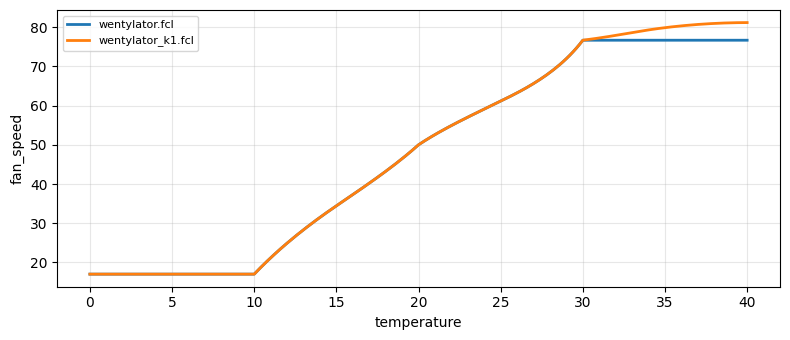

In [8]:
TEMPERATURY = [0, 5, 10, 15, 20, 25, 30, 35, 40]
tabela(["wentylator.fcl", "wentylator_k1.fcl"], "temperature", TEMPERATURY)
krzywa(["wentylator.fcl", "wentylator_k1.fcl"], "temperature")

**Pytanie 3a.** Co robi oryginalny sterownik powyżej 30 °C? Co zmieniło dodanie `very_hot`?

**Pytanie 3b.** Jaką prędkość daje sterownik przy 0 °C, a jaką przy 40 °C? Czy wentylator kiedykolwiek się wyłącza albo osiąga 100%? Dlaczego?

*Twoja odpowiedź:*

3a - Oryginalny sterownik powyżej 30°C nadal korzysta ze stanu hot, którego stopień przynależności wynosi 1 aż do 40°C. Dlatego wynik prędkości pozostaje praktycznie stały i wynosi 76,67%

Po dodaniu stanu very_hot sterownik rozpoznaje bardzo wysoką temperaturę i uruchamia dodatkową regułę ustawiającą wyjście na maximum. Prędkość wentylatora zaczyna wyraźnie rosnąć.

3b - Przy 0°C prędkość wynosi 17,03%, a przy 40°C w wersji z very_hot 95,03%

Wentylator nie wyłącza się, ponieważ dla niskiej temperatury działa reguła cold -> low, a funkcja przynależności low ma niezerowy obszar. Wartość 100% nie jest osiągana przy metodzie COG, ponieważ metoda ta wyznacza środek ciężkości całego aktywnego zbioru wyjściowego, a nie jego skrajny punkt.

---
## 4. Trzy konfiguracje

**Zadanie 3A.** Przetestuj sterownik z innymi ustawieniami. Każda konfiguracja to osobny plik FCL, w którym zmieniasz **jedną** rzecz:

| ustawienie w FCL | co określa | wariant do sprawdzenia |
|---|---|---|
| `ACT` | implikacja: jak siła reguły zmienia jej wniosek | `PROD` zamiast `MIN` |
| `METHOD` | wyostrzanie: jak z kształtu zrobić jedną liczbę | `MM` (środek maksimum) zamiast `COG` |
| `ACCU` | suma zbiorów na wyjściu: jak łączyć wnioski reguł | `BSUM` (suma ograniczona) zamiast `MAX` |

Funkcja `wariant` tworzy kopię pliku ze zmienionym ustawieniem. Możesz też skopiować plik ręcznie i zmienić jedną linijkę.

Zapisano wentylator_k2.fcl: ACT = PROD
Zapisano wentylator_k3.fcl: METHOD = MM
Zapisano wentylator_k4.fcl: ACCU = BSUM
 temperature  wentylator_k1  wentylator_k2  wentylator_k3  wentylator_k4
           0          17.03          17.03          10.00          17.03
           5          17.03          17.03          10.00          17.03
          10          17.03          17.03          10.00          17.03
          15          34.44          31.08          30.93          34.50
          20          50.00          50.00          50.00          50.00
          25          61.15          61.54          62.23          61.60
          30          76.67          76.67          80.00          76.67
          35          79.87          79.05          80.00          80.53
          40          81.17          81.17          90.00          81.70
          28          68.45          70.79          79.00          68.08
          32          77.90          77.61          80.00          78.65
     

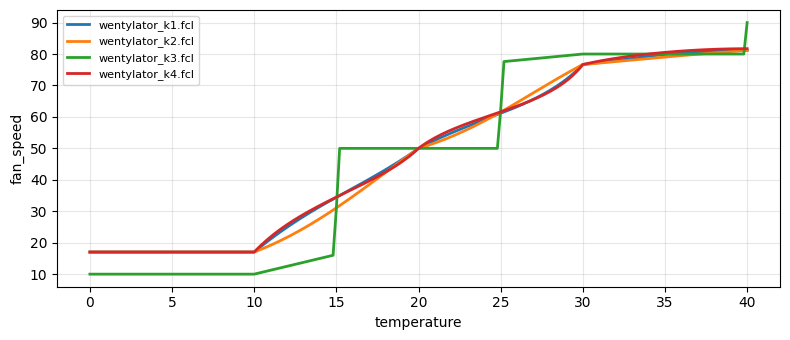

In [9]:
# TODO: utwórz trzy konfiguracje (po jednej zmianie każda)
k2 = wariant("wentylator_k1.fcl", "wentylator_k2.fcl", ACT="PROD")
k3 = wariant("wentylator_k1.fcl", "wentylator_k3.fcl", METHOD="MM")
k4 = wariant("wentylator_k1.fcl", "wentylator_k4.fcl", ACCU="BSUM")

KONFIGURACJE = ["wentylator_k1.fcl", k2,k3,k4]   # TODO: dopisz k3 i k4
tabela(KONFIGURACJE, "temperature", TEMPERATURY + [28, 32, 34])
krzywa(KONFIGURACJE, "temperature")

**Zadanie 3A (opis).** Dla każdej konfiguracji opisz: co zmieniłeś, przy jakich temperaturach wynik się zmienił i o ile. Która zmiana ma największy wpływ?

*Twoja odpowiedź:*

- K1 – konfiguracja podstawowa: ACT = MIN, METHOD = COG, ACCU = MAX. Jest to konfiguracja odniesienia
- K2 – ACT = PROD: zamiast przycinania zbioru wyjściowego zastosowano jego skalowanie. Zmiany są niewielkie, np. przy 15°C wynik spada z 34,44% do 31,08%, a przy 34°C rośnie z 81,93% do 84,24%
- K3 – METHOD = MM: wynik jest środkiem obszaru o maksymalnej przynależności. Zmiana jest wyraźna: przy 28°C wynik wynosi 79,00% zamiast 68,45%, a przy 40°C osiąga 100% zamiast 95,03%. Przy niskiej temperaturze wynik wynosi 10%
- K4 – ACCU = BSUM: zastosowano sumę ograniczoną zamiast maksimum przy łączeniu wniosków reguł. Różnice są małe, np. przy 34°C wynik wynosi 82,87% zamiast 81,93%.
Największy wpływ w badanych punktach ma zmiana metody wyostrzania z COG na MM. Zmienia ona sposób przekształcania całego zbioru rozmytego w jedną wartość liczbową.

---
## 5. Ocena sterownika

**Zadanie 3B.** Jak oceniasz działanie sterownika? Odnieś się do:
- czy prędkość rośnie z temperaturą płynnie, czy skokami,
- czy zakres prędkości (najmniejsza i największa) jest sensowny dla wentylatora,
- którą konfigurację wybrałbyś do prawdziwego urządzenia i dlaczego.

*Twoja odpowiedź:*

Prędkość wentylatora zmienia się na ogół płynnie, ponieważ funkcje przynależności sąsiadujących stanów nakładają się na siebie. Niektóre fragmenty charakterystyki mogą jednak być bardziej strome

Zakres prędkości od około 17% do 95% w konfiguracji K1 jest dość szeroki i pozwala dostosować pracę wentylatora do temperatury. Wentylator nie wyłącza się całkowicie

Do rzeczywistego urządzenia wybrałbym konfigurację K1 z metodą COG. Daje ona płynne przejścia i stabilny wynik. Przed zastosowaniem w praktyce należałoby jeszcze sprawdzić działanie urządzenia i dobrać zakres prędkości do konkretnego wentylatora.

---
## 6. Drugie wejście: wilgotność

Przy wysokiej wilgotności to samo ciepło jest bardziej uciążliwe, więc wentylator powinien kręcić się szybciej. Dodajemy do Twojego sterownika z części 2 drugie wejście `humidity` (wilgotność powietrza, 0–100%).

### 6.1 Rozszerzenie pliku

Nie musisz przepisywać całego pliku. Funkcja `rozszerz` bierze `wentylator_k1.fcl` i wkleja we właściwe miejsca trzy fragmenty, które piszesz w FCL:
1. nowe wejście w `VAR_INPUT` (gotowe),
2. blok `FUZZIFY humidity` z trzema stanami: `dry`, `normal`, `humid`,
3. co najmniej dwie nowe reguły, np. „ciepło **i** wilgotno → szybko”, „gorąco **i** wilgotno → maksimum”.

Zapisano wentylator_h.fcl – plik wczytuje się poprawnie.


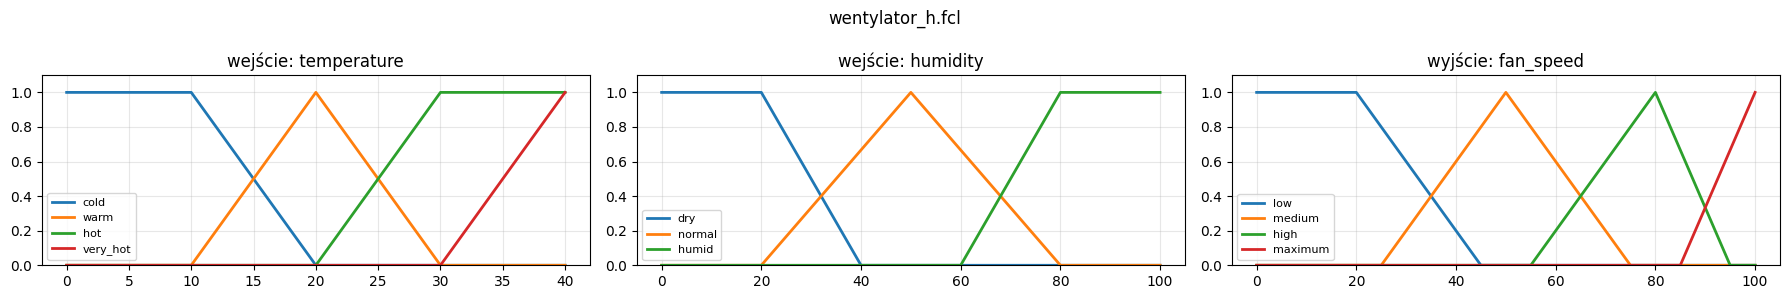

In [10]:
NOWE_WEJSCIE = "humidity : REAL;     (* wilgotność [%] *)"

# TODO: uzupełnij punkty (x, μ) – sąsiednie stany muszą się nakładać
NOWY_FUZZIFY = """
FUZZIFY humidity
    RANGE := (0 .. 100);
    TERM dry    := (0, 1) (20, 1) (40, 0);
    TERM normal := (20, 0) (50, 1) (80, 0);
    TERM humid  := (60, 0) (80, 1) (100, 1);
END_FUZZIFY
"""

# TODO: dopisz co najmniej dwie reguły z humidity (numeruj dalej: RULE 5, RULE 6, ...)
NOWE_REGULY = """
RULE 5 : IF temperature IS warm AND humidity IS humid THEN fan_speed IS high;
RULE 6 : IF temperature IS hot AND humidity IS humid THEN fan_speed IS maximum;
"""

rozszerz("wentylator_k1.fcl", "wentylator_h.fcl",
         wejscie=NOWE_WEJSCIE, fuzzify=NOWY_FUZZIFY, reguly=NOWE_REGULY)
rysuj_zbiory("wentylator_h.fcl")

**Testy.** Ta sama temperatura przy suchym (20%) i wilgotnym (90%) powietrzu, a potem wilgotność od 0 do 100% przy stałych 25 °C.

Powietrze suche (humidity = 20):
 temperature  wentylator_h
           0         17.03
           5         17.03
          10         17.03
          15         34.44
          20         50.00
          25         61.15
          30         76.67
          35         79.87
          40         81.17

Powietrze wilgotne (humidity = 90):
 temperature  wentylator_h
           0         17.03
           5         17.03
          10         17.03
          15         45.58
          20         61.54
          25         65.26
          30         81.17
          35         81.17
          40         81.17

Stała temperatura 25 °C:
    humidity  wentylator_h
           0         61.15
          20         61.15
          40         61.15
          60         61.15
          75         65.26
          90         65.26
         100         65.26


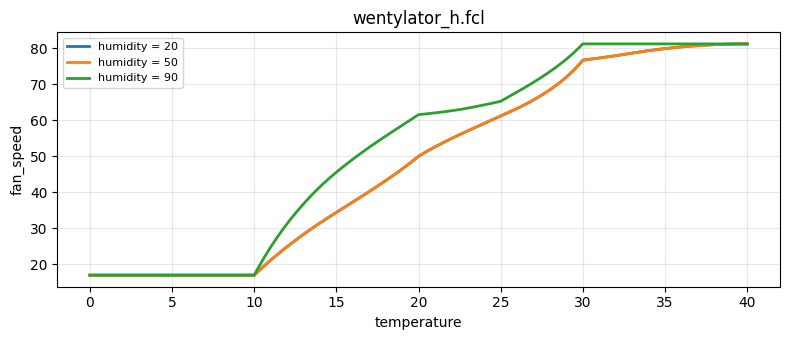

In [11]:
print("Powietrze suche (humidity = 20):")
tabela("wentylator_h.fcl", "temperature", TEMPERATURY, humidity=20)
print("\nPowietrze wilgotne (humidity = 90):")
tabela("wentylator_h.fcl", "temperature", TEMPERATURY, humidity=90)
print("\nStała temperatura 25 °C:")
tabela("wentylator_h.fcl", "humidity", [0, 20, 40, 60, 75, 90, 100], temperature=25)
krzywe("wentylator_h.fcl", "temperature", "humidity", [20, 50, 90])

**Pytanie 6a.** O ile wilgotne powietrze zwiększa prędkość przy 25 °C? Czy to dużo, czy mało?

**Pytanie 6b.** Czy wilgotność cokolwiek zmienia przy 10 °C? Dlaczego?

**Pytanie 6c.** Reguła 2 („warm → medium”) nic nie wie o wilgotności. Co robi, gdy powietrze jest wilgotne? Jak to wpływa na wynik z pytania 6a?

*Twoja odpowiedź:*

6a - Przy 25°C i wilgotności 20% prędkość wynosi 61,15%, a przy wilgotności 90% wynosi 65,26%. Wzrost wynosi 4,11 punktu procentowego.  to niewielka zmiana

6b - Przy 10°C wilgotność nie zmienia wyniku. Działająca reguła dotyczy stanu cold, a dodatkowe reguły uwzględniające wilgotność odnoszą się do stanów warm i hot

6c - Reguła 2 (warm -> medium) nadal działa niezaleznie od wilgotności. Przy wilgotnym powietrzu aktywuje się również dodatkowa reguła warm AND humid -> high. Oba wnioski są łączone przez operator ACCU, dlatego wynik jest kompromisem między średnią i wysoką prędkością.

### 6.2 Poprawka: stare reguły tylko dla niewilgotnego powietrza

Zmień reguły 2 i 3 tak, żeby działały tylko, gdy powietrze **nie** jest wilgotne. FCL ma do tego słowo `NOT`:

`RULE 2 : IF temperature IS warm AND humidity IS NOT humid THEN fan_speed IS medium;`

Komórka poniżej robi kopię pliku i zamienia w niej tekst reguł.

Stała temperatura 25 °C:
    humidity  wentylator_h  wentylator_h2
           0         61.15          61.15
          20         61.15          61.15
          40         61.15          61.15
          60         61.15          61.15
          75         65.26          69.75
          90         65.26          80.27
         100         65.26          80.27


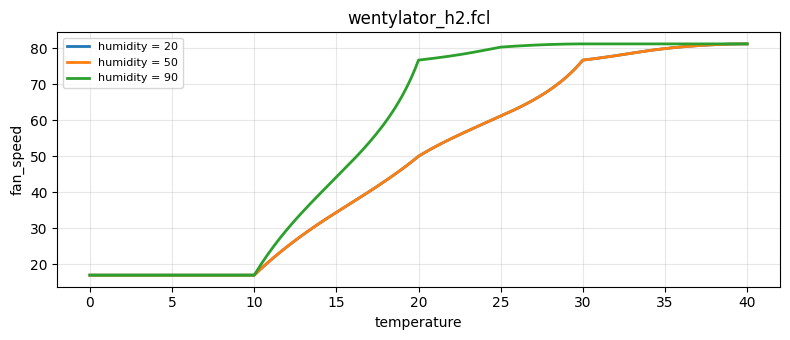

In [12]:
tekst = open("wentylator_h.fcl", encoding="utf-8").read()
# TODO: zamień reguły 2 i 3 (tekst przed zamianą musi być DOKŁADNIE taki jak w Twoim pliku)
tekst = tekst.replace( "RULE 2 : IF temperature IS warm THEN fan_speed IS medium;",
                        "RULE 2 : IF temperature IS warm AND humidity IS NOT humid THEN fan_speed IS medium;")
tekst = tekst.replace("RULE 3 : IF temperature IS hot THEN fan_speed IS high;",
                      "RULE 3 : IF temperature IS hot AND humidity IS NOT humid THEN fan_speed IS high;")
open("wentylator_h2.fcl", "w", encoding="utf-8").write(tekst)

print("Stała temperatura 25 °C:")
tabela(["wentylator_h.fcl", "wentylator_h2.fcl"], "humidity", [0, 20, 40, 60, 75, 90, 100], temperature=25)
krzywe("wentylator_h2.fcl", "temperature", "humidity", [20, 50, 90])

**Pytanie 6d.** Jak zmienił się wynik przy 25 °C i wilgotności 90% po poprawce? Dlaczego?

**Pytanie 6e.** Pełna baza reguł dla 4 stanów temperatury i 3 stanów wilgotności ma 4 × 3 = 12 reguł. Ile reguł ma Twój sterownik? Czy przy dwóch wejściach logika rozmyta daje coś, czego nie dałaby zwykła funkcja temperatury?

*Twoja odpowiedź:*

6в - Przy 25°C i wilgotności 90% wynik przed poprawką wynosi 65,26%, a po poprawce 80,27%. Prędkość wzrosła o 15,01 punktu procentowego

Po poprawce reguła 2 nie uruchamia już stanu medium, gdy wilgotność jest wysoka. Pozostaje dodatkowa reguła warm AND humid -> high, dlatego wynik jest większy

6е - Mój sterownik ma 6 reguł: 4 dotyczące temperatury (cold, warm, hot, very_hot) oraz 2 dodatkowe reguły uwzględniające wilgotność.

Pełna baza reguł dla 4 stanów temperatury i 3 stanów wilgotności zawierałaby 12 reguł. Logika rozmyta z dwoma wejściami pozwala uwzględnić jednocześnie temperaturę i wilgotność. Dzięki temu wentylator może pracować szybciej przy tej samej temperaturze, gdy powietrze jest bardziej wilgotne. Zwykła funkcja zależna tylko od temperatury nie uwzględniałaby tej różnicy.

---
## Do oddania

1. Pliki FCL: `wentylator_k1.fcl` (z `very_hot`) oraz co najmniej dwa warianty (`wentylator_k2.fcl`, `wentylator_k3.fcl`, …). W Colab: kliknij plik w panelu po lewej → „Pobierz”.
2. Pliki z wilgotnością: `wentylator_h.fcl` i `wentylator_h2.fcl`.
3. Ten notebook z wynikami i odpowiedziami zapisany jako PDF: Plik → Drukuj → Zapisz jako PDF.